# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Suhail Ainur Rofiq | 5054251046 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
%pip install torch
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim 
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 1.6/126.7 MB 9.8 MB/s eta 0:00:13
    --------------------------------------- 2.4/126.7 MB 6.0 MB/s eta 0:00:21
   - -------------------------------------- 4.7/126.7 MB 8.3 MB/s eta 0:00:15
   - -------------------------------------- 5.5/126.7 MB 6.7 MB/s eta 0:00:19
   -- ------------------------------------- 7.3/126.7 MB 7.2 MB/s eta 0:00:17
   -- ------------------------------------- 9.2/126.7 MB 7.3 MB/s eta 0:00:17
   --- ------------------------------------ 10.5/126.7 MB 7.1 MB/s eta 0:00:17
   --- ------------------------------------ 12.6/126.7 MB 7.4 MB/s eta 0:00:16
   ---- ----------------------------------- 14.4/126.7 MB 7.6 MB/s eta 0:00:15
   ---- ----------------------------------- 15.7/126.7 MB 7.4 MB/s eta 0:00:15
   ----- -----


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('Churn_Modelling.csv')
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

Series([], dtype: int64)


<Axes: xlabel='Exited', ylabel='count'>

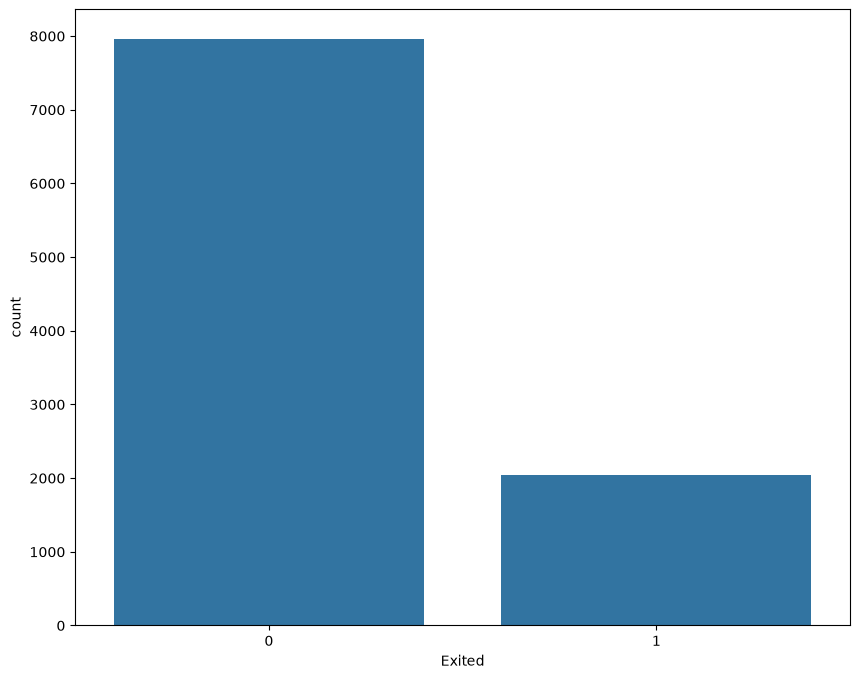

In [9]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(10, 8))

sns.countplot(
    data = df,
    x = 'Exited'
)

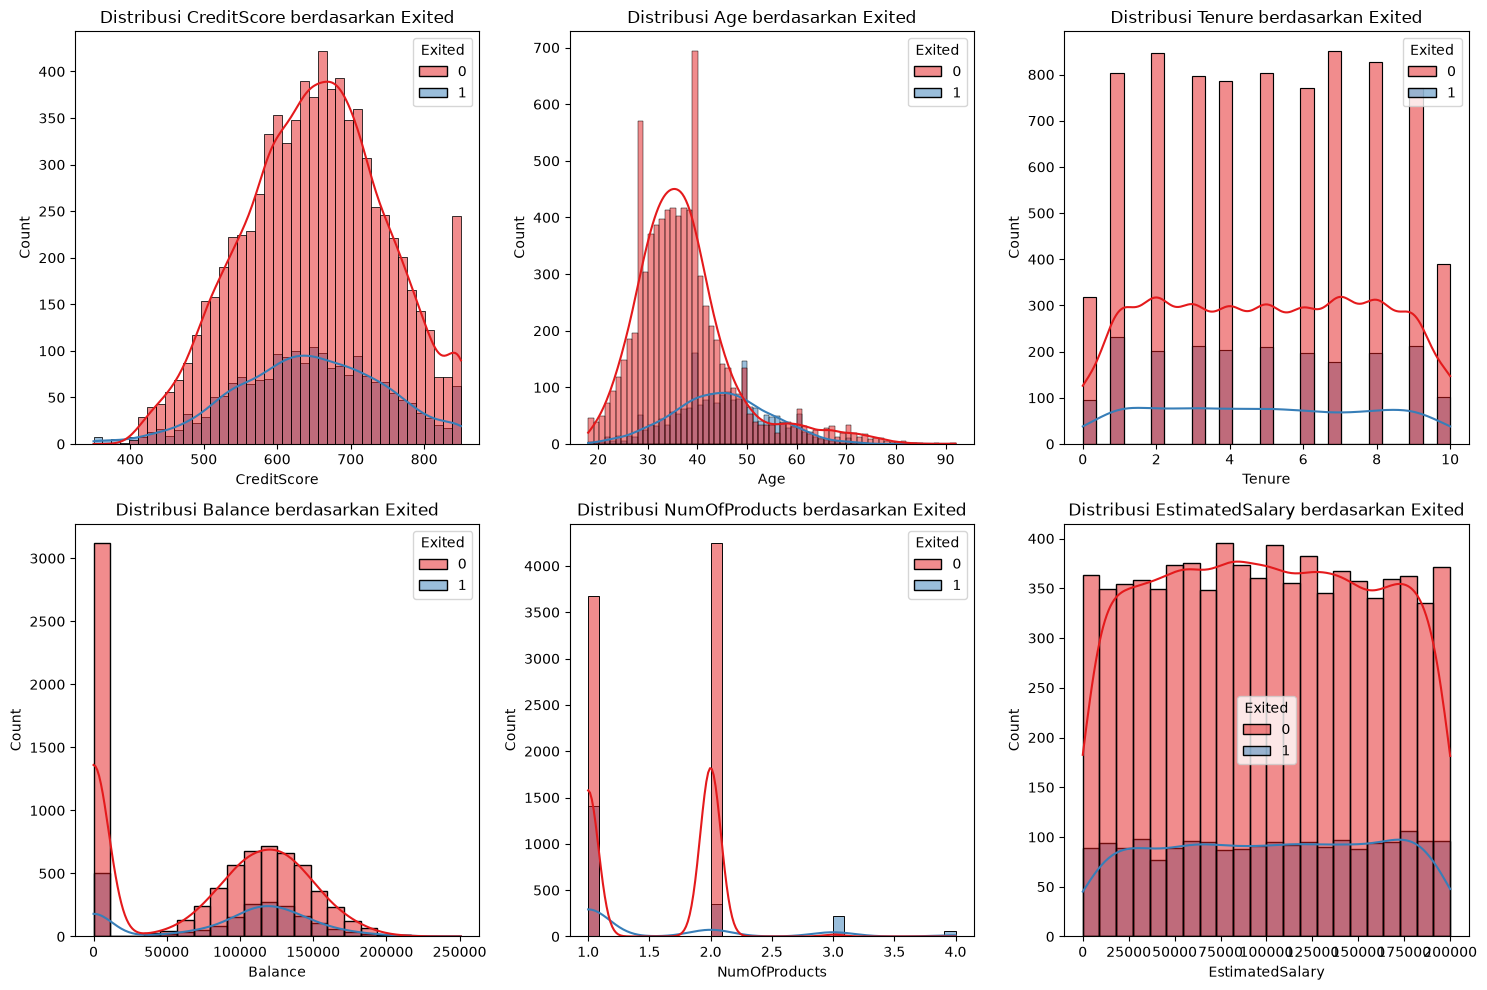

In [13]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
kolom_numerik = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    sns.histplot(
        data=df,
        x=col,
        hue='Exited',
        kde=True,
        ax=axes[i],
        palette='Set1'
    )
    axes[i].set_title(f'Distribusi {col} berdasarkan Exited')

plt.tight_layout()
plt.show()

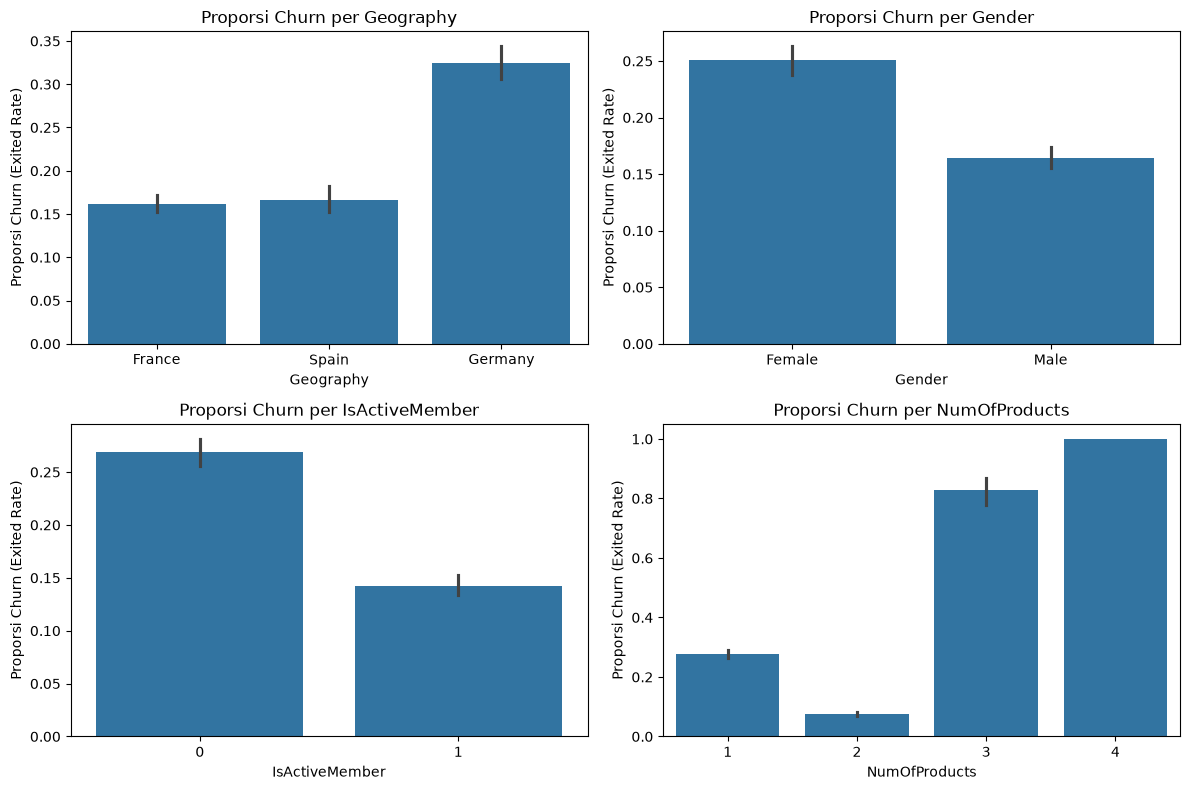

In [15]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
kolom_kategorikal = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
axes = axes.flatten()
for i, col in enumerate(kolom_kategorikal):
    sns.barplot(data=df, x=col, y='Exited', ax=axes[i])
    axes[i].set_title(f'Proporsi Churn per {col}')
    axes[i].set_ylabel('Proporsi Churn (Exited Rate)')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [16]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


Fitur tersebut di drop karena tidak berpengaruh pada hasil prediksi karena hanya fitur identitas

In [17]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df.drop(columns=['Exited'])
y = df['Exited']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(f"Jumlah data Train : {X_train.shape[0]} ({X_train.shape[0]/len(df)*100:.0f}%)")
print(f"Jumlah data Val   : {X_val.shape[0]} ({X_val.shape[0]/len(df)*100:.0f}%)")
print(f"Jumlah data Test  : {X_test.shape[0]} ({X_test.shape[0]/len(df)*100:.0f}%)")   

Jumlah data Train : 7000 (70%)
Jumlah data Val   : 1500 (15%)
Jumlah data Test  : 1500 (15%)


In [19]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
scaler = StandardScaler()
geo_encoder = OneHotEncoder(sparse_output=False)
gender_encoder = OneHotEncoder(drop='first', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', scaler, kolom_numerik),
        ('geo', geo_encoder, ['Geography']),
        ('gender', gender_encoder, ['Gender'])
    ],
    remainder='passthrough'
)

X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep   = preprocessor.transform(X_val)
X_test_prep  = preprocessor.transform(X_test)

print(f"X_train shape : {X_train_prep.shape}")
print(f"X_val shape   : {X_val_prep.shape}")
print(f"X_test shape  : {X_test_prep.shape}")

X_train shape : (7000, 12)
X_val shape   : (1500, 12)
X_test shape  : (1500, 12)


In [ ]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.
X_train_tensor = torch.tensor(X_train_prep, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_val_tensor   = torch.tensor(X_val_prep, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
X_test_tensor  = torch.tensor(X_test_prep, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

print(f"Bentuk X_train tensor: {X_train_tensor.shape}")
print(f"Bentuk y_train tensor: {y_train_tensor.shape}")
print(f"Jumlah batch per epoch di train_loader: {len(train_loader)} batch (masing-masing ~{batch_size} data)")

Bentuk X_train tensor: torch.Size([7000, 12])
Bentuk y_train tensor: torch.Size([7000, 1])
Jumlah batch per epoch di train_loader: 110 batch (masing-masing ~64 data)


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [21]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_prep, y_train)

y_pred_lr = lr_model.predict(X_test_prep)
y_prob_lr = lr_model.predict_proba(X_test_prep)[:, 1]

print("Prediksi 5 label pertama :", y_pred_lr[:5])
print("Probabilitas 5 data awal :", np.round(y_prob_lr[:5], 4))

Prediksi 5 label pertama : [0 0 0 0 0]
Probabilitas 5 data awal : [0.2355 0.0485 0.0736 0.1861 0.1144]


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [22]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).
class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.network(x)

input_dim = X_train_prep.shape[1]
model_simple = SimpleANN(input_dim)

print(model_simple)
print("Total parameter:", sum(p.numel() for p in model_simple.parameters()))

SimpleANN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Total parameter: 225


In [23]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.
def train_model(model, train_loader, X_train, y_train, X_val, y_val, criterion, optimizer, epochs=50):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        # 1. Training batch (hanya 4 baris inti PyTorch)
        model.train()
        for X_b, y_b in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(X_b), y_b)
            loss.backward()
            optimizer.step()
            
        # 2. Hitung evaluasi di akhir epoch (sesuai instruksi: model.eval & torch.no_grad)
        model.eval()
        with torch.no_grad():
            # Evaluasi Train Set
            out_tr = model(X_train)
            loss_tr = criterion(out_tr, y_train).item()
            acc_tr = ((torch.sigmoid(out_tr) >= 0.5) == y_train).float().mean().item()
            
            # Evaluasi Validation Set
            out_val = model(X_val)
            loss_val = criterion(out_val, y_val).item()
            acc_val = ((torch.sigmoid(out_val) >= 0.5) == y_val).float().mean().item()

        # Simpan ke history
        history['train_loss'].append(loss_tr)
        history['val_loss'].append(loss_val)
        history['train_acc'].append(acc_tr)
        history['val_acc'].append(acc_val)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {loss_tr:.4f}, Acc: {acc_tr:.4f} | Val Loss: {loss_val:.4f}, Acc: {acc_val:.4f}")
            
    return history

# Jalankan Pelatihan
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_simple.parameters(), lr=0.001)

history_simple = train_model(
    model_simple, train_loader,
    X_train_tensor, y_train_tensor,
    X_val_tensor, y_val_tensor,
    criterion, optimizer, epochs=50
)

Epoch 01/50 | Train Loss: 0.4911, Acc: 0.7963 | Val Loss: 0.4932, Acc: 0.7960
Epoch 10/50 | Train Loss: 0.3647, Acc: 0.8450 | Val Loss: 0.3515, Acc: 0.8507
Epoch 20/50 | Train Loss: 0.3513, Acc: 0.8519 | Val Loss: 0.3361, Acc: 0.8533
Epoch 30/50 | Train Loss: 0.3462, Acc: 0.8560 | Val Loss: 0.3326, Acc: 0.8547
Epoch 40/50 | Train Loss: 0.3431, Acc: 0.8556 | Val Loss: 0.3306, Acc: 0.8593
Epoch 50/50 | Train Loss: 0.3411, Acc: 0.8566 | Val Loss: 0.3283, Acc: 0.8607


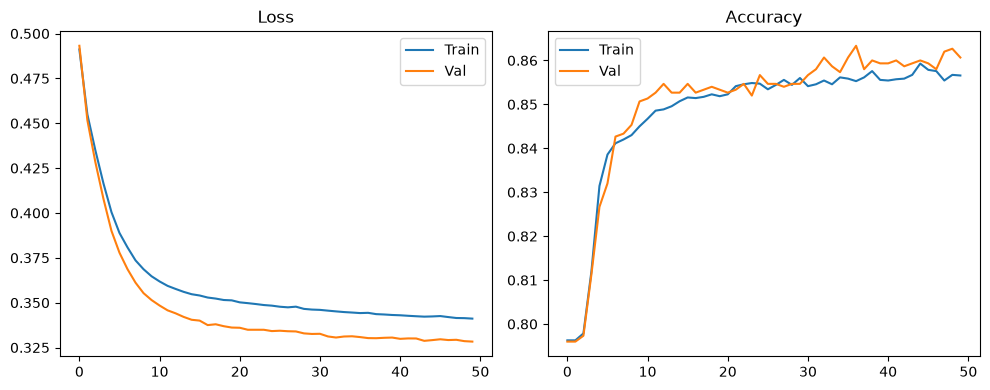

In [24]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_simple['train_loss'], label='Train')
plt.plot(history_simple['val_loss'], label='Val')
plt.title('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_simple['train_acc'], label='Train')
plt.plot(history_simple['val_acc'], label='Val')
plt.title('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.
model_simple.eval()
with torch.no_grad():
    probs = torch.sigmoid(model_simple(X_test_tensor))
    preds = (probs >= 0.5).float()

y_prob_ann_simple = probs.squeeze().numpy()
y_pred_ann_simple = preds.squeeze().numpy()

print("5 Probabilitas Churn Awal :", np.round(y_prob_ann_simple[:5], 4))
print("5 Label Prediksi Awal     :", y_pred_ann_simple[:5].astype(int))

5 Probabilitas Churn Awal : [0.2003 0.0121 0.0601 0.0716 0.2381]
5 Label Prediksi Awal     : [0 0 0 0 0]


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [26]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

# Class Deep ANN dengan 2 hidden layer dan Dropout
class DeepANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.3),  # Matikan 30% neuron secara acak saat training
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),  # Mencegah ketergantungan antar neuron (overfitting)
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.network(x)

# Inisialisasi model dan hitung parameter
model_deep = DeepANN(X_train_prep.shape[1])
print(model_deep)
print("Total parameter:", sum(p.numel() for p in model_deep.parameters()))

DeepANN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Total parameter: 961


Epoch 01/50 | Train Loss: 0.4700, Acc: 0.7963 | Val Loss: 0.4680, Acc: 0.7960
Epoch 10/50 | Train Loss: 0.3622, Acc: 0.8473 | Val Loss: 0.3512, Acc: 0.8460
Epoch 20/50 | Train Loss: 0.3500, Acc: 0.8547 | Val Loss: 0.3400, Acc: 0.8553
Epoch 30/50 | Train Loss: 0.3406, Acc: 0.8627 | Val Loss: 0.3329, Acc: 0.8620
Epoch 40/50 | Train Loss: 0.3364, Acc: 0.8631 | Val Loss: 0.3302, Acc: 0.8667
Epoch 50/50 | Train Loss: 0.3336, Acc: 0.8643 | Val Loss: 0.3284, Acc: 0.8693


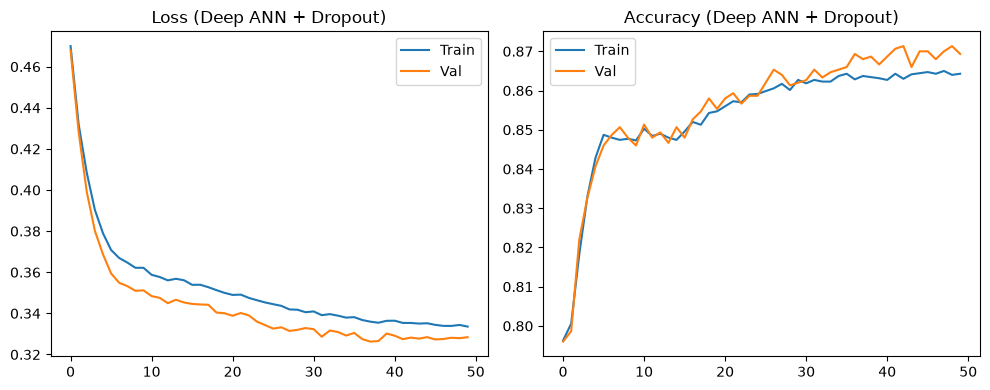

In [27]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

# Latih model memakai fungsi train_model yang sudah dibuat di 3.2
optimizer = torch.optim.Adam(model_deep.parameters(), lr=0.001)

history_deep = train_model(
    model_deep, train_loader,
    X_train_tensor, y_train_tensor,
    X_val_tensor, y_val_tensor,
    criterion, optimizer, epochs=50
)

# Visualisasi kurva loss dan akurasi
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_deep['train_loss'], label='Train')
plt.plot(history_deep['val_loss'], label='Val')
plt.title('Loss (Deep ANN + Dropout)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_deep['train_acc'], label='Train')
plt.plot(history_deep['val_acc'], label='Val')
plt.title('Accuracy (Deep ANN + Dropout)')
plt.legend()

plt.tight_layout()
plt.show()

In [31]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

# Mode evaluasi tanpa gradien
model_deep.eval()
with torch.no_grad():
    probs = torch.sigmoid(model_deep(X_test_tensor))
    preds = (probs >= 0.5).float()

# Simpan probabilitas dan label untuk evaluasi akhir di bab 4
y_prob_ann_deep = probs.squeeze().numpy()
y_pred_ann_deep = preds.squeeze().numpy()

print("5 Probabilitas Churn Awal :", np.round(y_prob_ann_deep[:5], 4))
print("5 Label Prediksi Awal     :", y_pred_ann_deep[:5].astype(int))

5 Probabilitas Churn Awal : [0.192  0.0194 0.0657 0.0882 0.254 ]
5 Label Prediksi Awal     : [0 0 0 0 0]


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [28]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# 1. Hitung rasio bobot kelas (jumlah kelas 0 / jumlah kelas 1 pada train set)
num_neg = (y_train_tensor == 0).sum().item()
num_pos = (y_train_tensor == 1).sum().item()
pos_weight = num_neg / num_pos
print(f"Rasio bobot kelas positif (pos_weight): {pos_weight:.2f}")

# 2. Buat ulang model DeepANN agar bobot direset dari awal
model_weighted = DeepANN(X_train_prep.shape[1])

# 3. Setup loss function dengan pos_weight dan optimizer
criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]))
optimizer = torch.optim.Adam(model_weighted.parameters(), lr=0.001)

# 4. Latih model dengan train_model
history_weighted = train_model(
    model_weighted, train_loader,
    X_train_tensor, y_train_tensor,
    X_val_tensor, y_val_tensor,
    criterion_weighted, optimizer, epochs=50
)

Rasio bobot kelas positif (pos_weight): 3.91
Epoch 01/50 | Train Loss: 1.0313, Acc: 0.6443 | Val Loss: 1.0287, Acc: 0.6387
Epoch 10/50 | Train Loss: 0.7560, Acc: 0.7704 | Val Loss: 0.7284, Acc: 0.7573
Epoch 20/50 | Train Loss: 0.7340, Acc: 0.7826 | Val Loss: 0.7112, Acc: 0.7773
Epoch 30/50 | Train Loss: 0.7236, Acc: 0.7990 | Val Loss: 0.7006, Acc: 0.8020
Epoch 40/50 | Train Loss: 0.7128, Acc: 0.8013 | Val Loss: 0.6889, Acc: 0.7967
Epoch 50/50 | Train Loss: 0.7120, Acc: 0.8106 | Val Loss: 0.6903, Acc: 0.8080


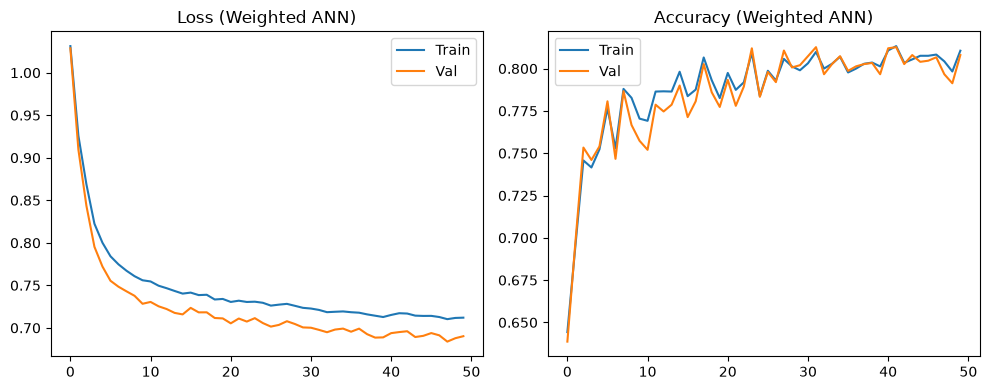

5 Probabilitas Churn Awal : [0.4582 0.1007 0.1793 0.2647 0.519 ]
5 Label Prediksi Awal     : [0 0 0 0 1]


In [29]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

# 1. Visualisasi learning curve train vs validation
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_weighted['train_loss'], label='Train')
plt.plot(history_weighted['val_loss'], label='Val')
plt.title('Loss (Weighted ANN)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_weighted['train_acc'], label='Train')
plt.plot(history_weighted['val_acc'], label='Val')
plt.title('Accuracy (Weighted ANN)')
plt.legend()

plt.tight_layout()
plt.show()

# 2. Prediksi pada test set
model_weighted.eval()
with torch.no_grad():
    probs = torch.sigmoid(model_weighted(X_test_tensor))
    preds = (probs >= 0.5).float()

# 3. Simpan probabilitas dan label untuk evaluasi bab 4
y_prob_ann_weighted = probs.squeeze().numpy()
y_pred_ann_weighted = preds.squeeze().numpy()

print("5 Probabilitas Churn Awal :", np.round(y_prob_ann_weighted[:5], 4))
print("5 Label Prediksi Awal     :", y_pred_ann_weighted[:5].astype(int))

# 4. Evaluasi Model

In [32]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

# List nama model dan hasil prediksinya
models = ['Logistic Regression', 'Simple ANN', 'Deep ANN + Dropout', 'Weighted ANN']
preds = [y_pred_lr, y_pred_ann_simple, y_pred_ann_deep, y_pred_ann_weighted]

# Hitung metrik evaluasi untuk masing-masing model
eval_data = []
for name, pred in zip(models, preds):
    eval_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred)
    })

# Tampilkan perbandingan metrik dalam tabel DataFrame
df_eval = pd.DataFrame(eval_data)
df_eval

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.815333,0.645833,0.203279,0.309227
1,Simple ANN,0.866667,0.769231,0.491803,0.600000
2,Deep ANN + Dropout,0.866000,0.809524,0.445902,0.575053
3,Weighted ANN,0.810000,0.522321,0.767213,0.621514


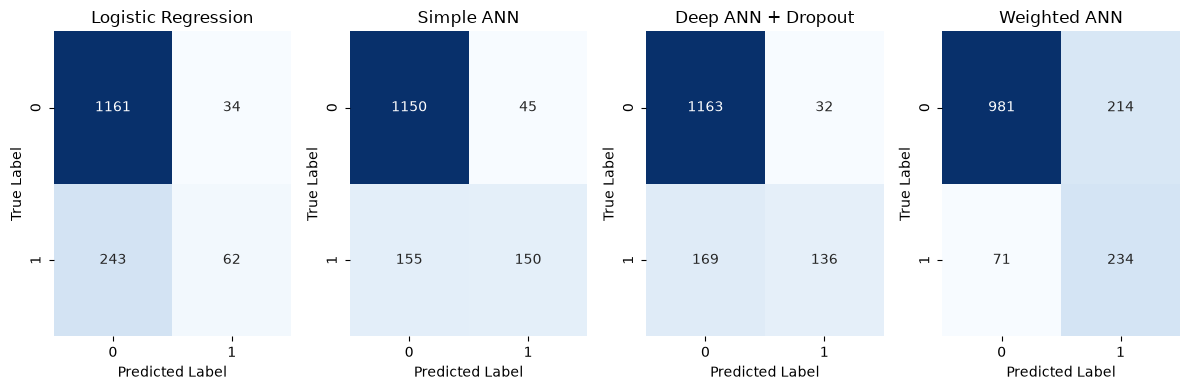

In [39]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

# Setup subplot 1 baris untuk 4 model
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

# Plot heatmap confusion matrix untuk setiap model
for ax, name, pred in zip(axes, models, preds):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

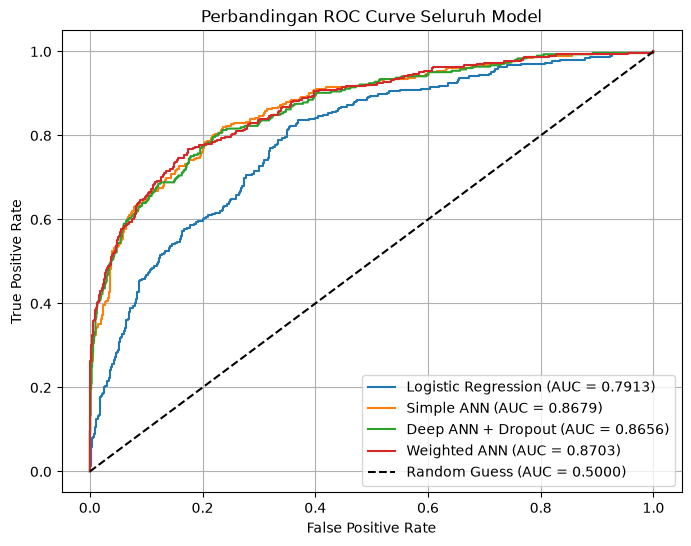

In [34]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

# List probabilitas prediksi untuk masing-masing model
probs = [y_prob_lr, y_prob_ann_simple, y_prob_ann_deep, y_prob_ann_weighted]

plt.figure(figsize=(8, 6))

# Plot ROC curve dan hitung AUC score untuk seluruh model
for name, prob in zip(models, probs):
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_score = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})')

# Garis referensi tebakan acak (random guess)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')
plt.title('Perbandingan ROC Curve Seluruh Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

### 1. Perbandingan Performa Antar Model
Berdasarkan hasil pengujian pada test set, berikut adalah perbandingan performa dari keempat model yang diuji:

1. Logistic Regression (Baseline): Memperoleh akurasi 81.53 persen, namun nilai Recall untuk kelas churn sangat rendah, yaitu hanya 20.33 persen dengan F1-Score 0.3092. Artinya, model linear ini gagal mendeteksi sekitar 80 persen nasabah yang sebenarnya keluar. Hal ini membuktikan bahwa model linear kesulitan membaca pola churn yang kompleks dan tidak seimbang.
2. Simple ANN: Memberikan peningkatan yang nyata dibanding baseline. Akurasinya naik menjadi 86.67 persen, Precision mencapai 76.92 persen, dan Recall naik ke 49.18 persen dengan F1-Score 0.6000. Jaringan saraf tiruan terbukti jauh lebih mampu menangkap hubungan antar fitur perbankan yang tidak berpola garis lurus.
3. Deep ANN dengan Dropout: Menghasilkan akurasi 86.60 persen dan nilai Precision paling tinggi, yaitu 80.95 persen. Model ini sangat berhati-hati dan tepat saat menebak nasabah akan churn sehingga jarang salah tebak. Namun, nilai Recall-nya sedikit turun ke 44.59 persen dengan F1-Score 0.5751.
4. Weighted ANN (Penanganan Data Imbalanced): Menjadi model terbaik untuk mendeteksi nasabah churn secara keseluruhan. Walaupun akurasinya sedikit turun menjadi 81.00 persen, Recall melonjak drastis hingga 76.72 persen dengan F1-Score tertinggi yaitu 0.6215. Model ini sukses menangkap sebagian besar nasabah yang benar-benar akan churn.

### 2. Bentuk Learning Curve (Overfitting dan Underfitting)
1. Simple ANN: Grafik loss untuk data latihan dan validasi sama-sama turun secara konsisten dan stabil. Jarak antara loss latihan dan validasi cukup dekat, menandakan model belajar dengan baik dan tidak mengalami masalah overfitting yang berarti.
2. Deep ANN dengan Dropout: Penambahan Dropout sebesar 0.3 terbukti efektif menjaga kestabilan model. Meskipun arsitekturnya lebih dalam, grafik loss validasi tetap berada dekat dengan loss latihan dan tidak berbalik naik. Ini menandakan Dropout berhasil mencegah model menghafal data latihan.
3. Weighted ANN: Nilai loss terlihat lebih tinggi secara angka karena fungsi loss mengalikan bobot kesalahan kelas churn sebesar 3.91 kali lipat. Walaupun fungsi penaltinya diberi bobot lebih berat, grafik loss latihan dan validasi tetap turun bersamaan secara stabil seiring bertambahnya epoch.

### 3. Pengaruh Penambahan Layer dan Dropout
1. Penambahan hidden layer dari 1 layer (16 neuron) menjadi 2 layer (32 dan 16 neuron) membantu model menyusun pemahaman fitur yang lebih mendalam dari data nasabah.
2. Penambahan Dropout 0.3 secara acak mematikan 30 persen neuron saat proses latihan. Hal ini memaksa jaringan saraf tiruan mencari pola yang lebih kokoh dan tidak bergantung pada satu fitur saja. Hasil positifnya terlihat langsung pada nilai Precision yang meningkat pesat hingga 80.95 persen.

### 4. Pengaruh Class Weight terhadap Precision dan Recall
1. Dataset ini memiliki ketidakseimbangan kelas yang cukup jauh, yaitu sekitar 80 persen nasabah bertahan dan hanya 20 persen nasabah yang churn. Pada model biasa, model cenderung cari aman dengan lebih sering menebak nasabah bertahan agar nilai akurasinya terlihat tinggi.
2. Dengan memasukkan bobot kelas (pos_weight) bernilai 3.91, model diberikan hukuman yang jauh lebih berat jika salah menebak nasabah yang sebenarnya churn.
3. Akibatnya terjadi pertukaran performa (trade off): nilai Recall melonjak tinggi dari 44 persen menjadi 76.72 persen, sedangkan Precision turun dari 80.95 persen ke 52.23 persen karena model menebak lebih agresif. Bagi pihak bank, hasil ini jauh lebih menguntungkan karena lebih baik mengontak nasabah yang salah diprediksi churn daripada membiarkan nasabah asli pergi tanpa sempat dicegah.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan
1. Artificial Neural Network (ANN) terbukti jauh lebih unggul dibandingkan model Logistic Regression dalam mengenali pola nasabah yang churn.
2. Penambahan hidden layer yang dipadukan dengan Dropout berhasil meningkatkan ketepatan tebakan (Precision) dan menjaga model agar tidak overfitting.
3. Penanganan data imbalanced dengan memberikan class weight pada fungsi loss adalah langkah paling penting pada proyek ini. Metode ini sukses melipatgandakan Recall hingga 76.72 persen serta menghasilkan F1-Score tertinggi yaitu 0.6215, sehingga model Weighted ANN menjadi model yang paling cocok digunakan untuk kebutuhan bisnis retensi nasabah.

### Saran
1. Melakukan penyesuaian ambang batas keputusan (threshold tuning). Menggeser batas probabilitas dari angka bawaan 0.5 bisa membantu mencari titik keseimbangan terbaik antara Precision dan Recall sesuai kebutuhan biaya promosi bank.
2. Mencoba teknik penyeimbangan data pada tingkat dataset, misalnya menggunakan metode SMOTE (Synthetic Minority Over-sampling Technique), lalu membandingkan hasilnya dengan metode class weight.
3. Melakukan eksperimen optimasi parameter lanjutan, seperti mencoba variasi learning rate scheduler atau menghentikan latihan otomatis dengan Early Stopping jika performa validasi sudah tidak membaik.